# Gaussian Process Regression

A non-parametric, Bayesian approach: instead of learning weights, put a prior over *functions* and condition it on the data. The result is a prediction **and an uncertainty** at every point.

With an RBF kernel `k(a, b) = variance · exp(−‖a − b‖² / 2·length_scale²)` (nearby inputs → similar outputs) and `K = k(X, X) + noise²·I`:

```
mean(x*) = k(x*, X) · K⁻¹ y
var(x*)  = k(x*, x*) − k(x*, X) · K⁻¹ · k(X, x*)
```

K is factored with a Cholesky decomposition rather than inverted directly. Near training points the std shrinks; far from them the prediction reverts to the prior (mean 0, std `√variance`).

- `length_scale`: how quickly the function wiggles. `variance`: output scale. `noise`: observation noise std.
- Hyperparameters are fixed here; picking them by maximizing marginal likelihood is a natural extension.
- Cost is O(n³), so it suits small datasets.

## Usage

```python
# (the class is defined in the Implementation section below)

gp = GaussianProcessRegressor(length_scale=1.0, variance=1.0, noise=0.1).fit(X_train, y_train)
mean, std = gp.predict(X_test, return_std=True)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _rbf_kernel(A, B, length_scale, variance):
    sq_dist = ((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2)
    return variance * np.exp(-0.5 * sq_dist / length_scale**2)


class GaussianProcessRegressor:
    """Gaussian process with an RBF kernel and a zero-mean prior. Predicts a mean *and* an
    uncertainty (std) for every point: wide away from the data, tight near it.

    noise is the std of the observation noise. Hyperparameters are fixed, not learned.

    ponytail: O(n^3) fit, O(n^2) memory, no marginal-likelihood tuning of the hyperparameters."""

    def __init__(self, length_scale=1.0, variance=1.0, noise=0.1):
        self.length_scale = length_scale
        self.variance = variance
        self.noise = noise
        self.X_train = None
        self.L = None
        self.alpha = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        K = _rbf_kernel(self.X_train, self.X_train, self.length_scale, self.variance)
        K += self.noise**2 * np.eye(len(y))
        self.L = np.linalg.cholesky(K)  # K = L L^T, stable way to "invert" K
        self.alpha = np.linalg.solve(self.L.T, np.linalg.solve(self.L, y))  # K^-1 y
        return self

    def predict(self, X, return_std=False):
        X = np.asarray(X, dtype=float)
        K_star = _rbf_kernel(X, self.X_train, self.length_scale, self.variance)
        mean = K_star @ self.alpha
        if not return_std:
            return mean
        v = np.linalg.solve(self.L, K_star.T)
        var = self.variance - (v**2).sum(axis=0)  # prior variance minus what the data explains
        return mean, np.sqrt(np.clip(var, 0.0, None))

## See it work

### 1. A distribution over functions

A GP does not return one curve but a **posterior over functions**: a mean prediction and an uncertainty. The band (±2σ) is **narrow near data and widens away from it**, which is exactly the behaviour you want from honest uncertainty.

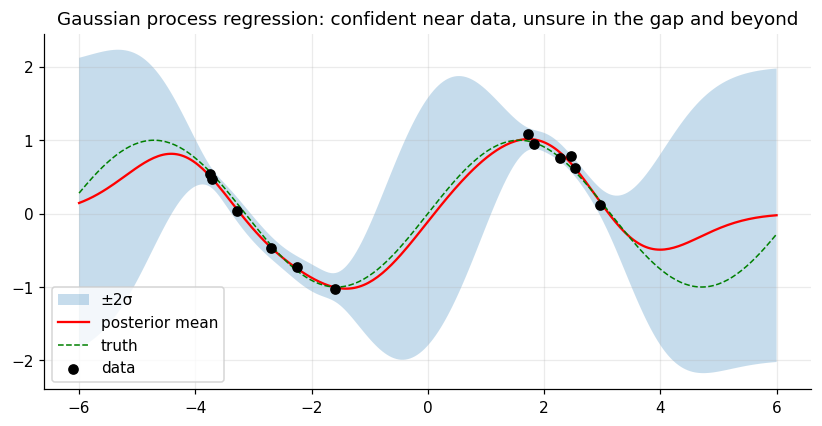

In [3]:
rng = np.random.default_rng(3)
x = np.sort(np.concatenate([rng.uniform(-4, -1, 6), rng.uniform(1.5, 3.5, 6)]))
y = np.sin(x) + rng.normal(scale=0.1, size=len(x))
xs = np.linspace(-6, 6, 300)[:, None]
gp = GaussianProcessRegressor(length_scale=1.0, variance=1.0, noise=0.1).fit(x[:, None], y)
mean, std = gp.predict(xs, return_std=True)

plt.figure(figsize=(9, 4.2))
plt.fill_between(xs[:, 0], mean - 2 * std, mean + 2 * std, alpha=0.25, label="±2σ")
plt.plot(xs, mean, "r", label="posterior mean"); plt.plot(xs, np.sin(xs), "g--", lw=1, label="truth"); plt.scatter(x, y, c="k", zorder=3, label="data")
plt.title("Gaussian process regression: confident near data, unsure in the gap and beyond"); plt.legend(); plt.show()

### 2. The length scale controls smoothness

`length_scale` says how far apart two inputs can be and still be strongly correlated. Too small: wiggly, overfits and is overconfident only right at the points. Too large: oversmooth.

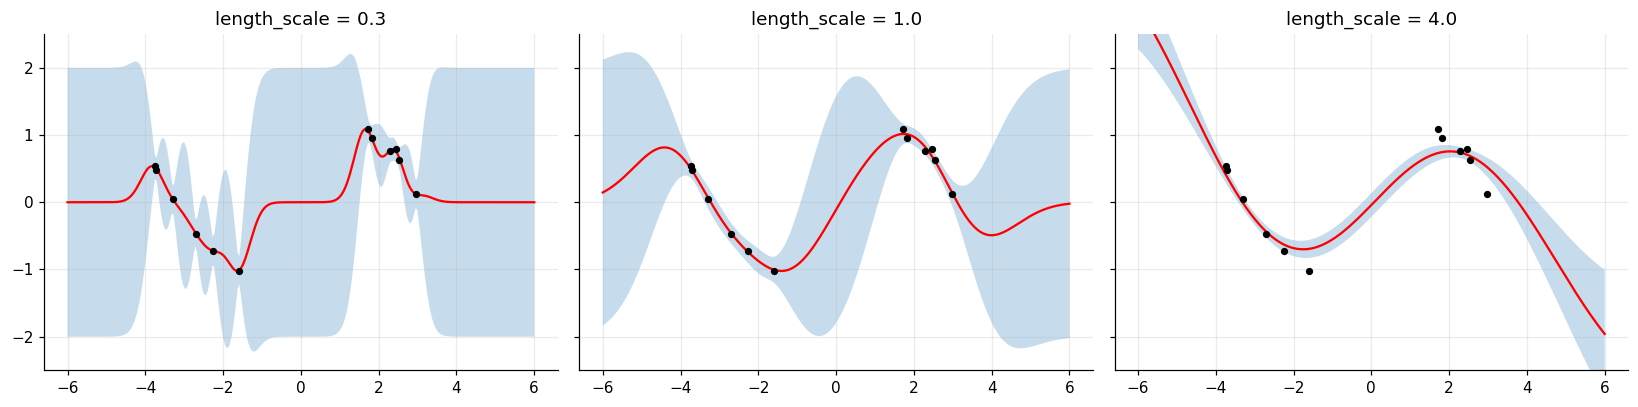

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, ls in zip(axes, [0.3, 1.0, 4.0]):
    g = GaussianProcessRegressor(length_scale=ls, variance=1.0, noise=0.1).fit(x[:, None], y)
    m, s = g.predict(xs, return_std=True)
    ax.fill_between(xs[:, 0], m - 2 * s, m + 2 * s, alpha=0.25); ax.plot(xs, m, "r"); ax.scatter(x, y, c="k", s=14, zorder=3)
    ax.set(title=f"length_scale = {ls}", ylim=(-2.5, 2.5))
plt.tight_layout(); plt.show()

### 3. Samples from the prior vs the posterior

Before seeing data, the GP is just random smooth functions. After conditioning on the observations, every plausible function is pinned near the data points (but free in the gaps).

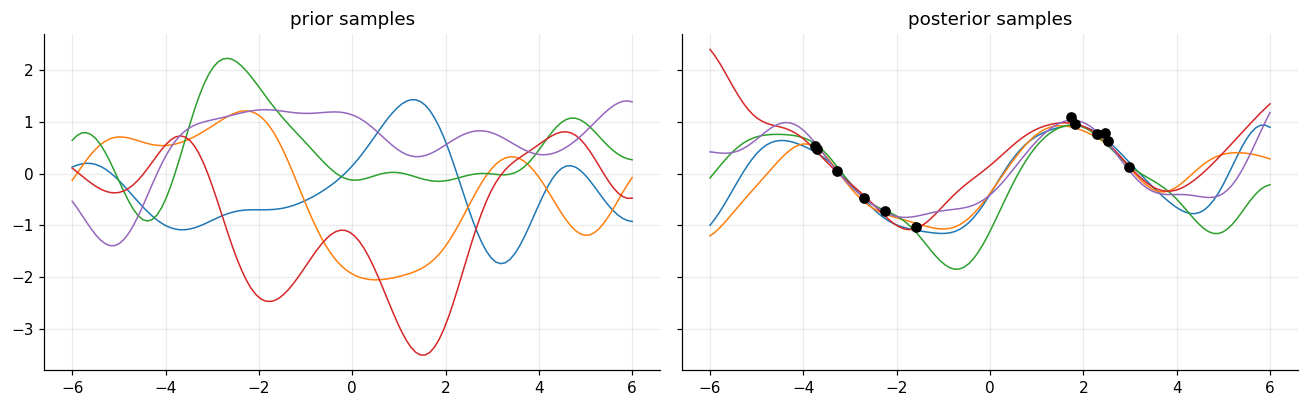

In [5]:
from scipy.linalg import cholesky

def rbf(A, B, ls=1.0, var=1.0):
    return var * np.exp(-0.5 * ((A[:, None] - B[None]) ** 2).sum(-1) / ls ** 2)

grid = np.linspace(-6, 6, 120)[:, None]
K = rbf(grid, grid) + 1e-8 * np.eye(120)
Ks = rbf(grid, x[:, None]); Kn = rbf(x[:, None], x[:, None]) + 0.1 ** 2 * np.eye(len(x))
post_mean = Ks @ np.linalg.solve(Kn, y); post_cov = K - Ks @ np.linalg.solve(Kn, Ks.T) + 1e-8 * np.eye(120)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, mu, cov, title in [(axes[0], np.zeros(120), K, "prior samples"), (axes[1], post_mean, post_cov, "posterior samples")]:
    ax.plot(grid, (mu[:, None] + cholesky(cov, lower=True) @ rng.normal(size=(120, 5))), lw=1); ax.set_title(title)
axes[1].scatter(x, y, c="k", zorder=3)
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor as SklearnGPR
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

rng = np.random.default_rng(0)
X = np.sort(rng.uniform(0, 6, size=(25, 1)), axis=0)
y = np.sin(X[:, 0]) + rng.normal(scale=0.1, size=25)
X_test = np.linspace(-1, 7, 80)[:, None]

length_scale, variance, noise = 1.0, 1.0, 0.1
ours = GaussianProcessRegressor(length_scale, variance, noise).fit(X, y)
# same kernel, hyperparameters frozen (no optimizer), so the two should agree to numerical precision
kernel = ConstantKernel(variance, "fixed") * RBF(length_scale, "fixed")
theirs = SklearnGPR(kernel=kernel, alpha=noise**2, optimizer=None).fit(X, y)

mean_o, std_o = ours.predict(X_test, return_std=True)
mean_t, std_t = theirs.predict(X_test, return_std=True)
print("max |mean diff| = %.2e, max |std diff| = %.2e" % (np.abs(mean_o - mean_t).max(), np.abs(std_o - std_t).max()))
print("std inside data range ~%.2f, outside (x=7) ~%.2f" % (std_o[np.argmin(np.abs(X_test[:, 0] - 3))], std_o[-1]))
assert np.allclose(mean_o, mean_t, atol=1e-6)
assert np.allclose(std_o, std_t, atol=1e-5)

max |mean diff| = 7.05e-15, max |std diff| = 3.83e-15
std inside data range ~0.07, outside (x=7) ~0.82


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_interpolates_training_points_when_noise_is_tiny():
    X = np.array([[0.0], [1.0], [2.0], [3.0]])
    y = np.array([0.0, 1.0, 0.0, -1.0])
    gp = GaussianProcessRegressor(length_scale=1.0, noise=1e-4).fit(X, y)
    assert np.allclose(gp.predict(X), y, atol=1e-3)


def test_uncertainty_is_small_near_data_and_large_far_away():
    X = np.array([[0.0], [1.0], [2.0]])
    y = np.sin(X[:, 0])
    gp = GaussianProcessRegressor(length_scale=1.0, variance=1.0, noise=0.05).fit(X, y)
    _, std_near = gp.predict(np.array([[1.0]]), return_std=True)
    _, std_far = gp.predict(np.array([[50.0]]), return_std=True)
    assert std_near[0] < 0.1
    assert abs(std_far[0] - 1.0) < 1e-6  # reverts to the prior std = sqrt(variance)


def test_far_from_data_mean_reverts_to_zero_prior():
    X = np.array([[0.0], [1.0]])
    gp = GaussianProcessRegressor().fit(X, np.array([5.0, 5.0]))
    assert abs(gp.predict(np.array([[100.0]]))[0]) < 1e-6

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_interpolates_training_points_when_noise_is_tiny
PASS test_uncertainty_is_small_near_data_and_large_far_away
PASS test_far_from_data_mean_reverts_to_zero_prior

all 3 tests passed


## Takeaways

- **Use it when** data is scarce (tens to a few thousand points) and you need calibrated uncertainty: Bayesian optimisation, surrogate modelling, small-data regression.
- **Cost:** `O(n³)` time and `O(n²)` memory (a Cholesky of the n×n kernel matrix), so it does not scale to big data.
- **Hyperparameters** (`length_scale`, `variance`, `noise`) are fixed by hand here; real GPs learn them by maximising the marginal likelihood.
- **Prediction:** mean `k*ᵀ(K + σ²I)⁻¹y`, variance `k** − k*ᵀ(K + σ²I)⁻¹k*`.
- **Interview line:** *"A GP puts a Gaussian prior over functions via a kernel; conditioning on data gives a Gaussian posterior with closed-form mean and variance."*